In [1]:
import re
import urllib.request
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader

In [2]:
torch.manual_seed(42)
np.random.seed(42)

In [3]:
url = 'https://wolnelektury.pl/media/book/txt/lalka-tom-pierwszy.txt'
raw_text = urllib.request.urlopen(url).read().decode('utf-8')

In [4]:
tekst = raw_text.replace('\r\n', '\n')

In [5]:
start_idx = tekst.find('Tom pierwszy')
end_idx = tekst.rfind('-')
if start_idx != -1 and end_idx != -1:
    tekst = tekst[start_idx:end_idx]

In [6]:
tekst = re.sub(r'\n{3,}', '\n\n', tekst).strip()

print(f"Długość tekstu po oczyszczeniu: {len(tekst)} znaków")
print("Przykładowy fragment po oczyszczeniu:")
print("-" * 40)
print(tekst[:350])
print("-" * 40)

Długość tekstu po oczyszczeniu: 774165 znaków
Przykładowy fragment po oczyszczeniu:
----------------------------------------
Bolesław Prus

Lalka

ISBN 978-83-288-2673-1

Tom I

I. Jak wygląda firma J. Mincel i S. Wokulski przez szkło butelek?

W początkach roku 1878, kiedy świat polityczny zajmował się pokojem san-stefańskim, wyborem nowego papieża albo szansami europejskiej wojny, warszawscy kupcy tudzież inteligencja pewnej okolicy Krakowskiego Przedmieścia niemniej g
----------------------------------------


In [7]:
n = len(tekst)
train_end = int(0.8 * n)
val_end = int(0.9 * n)

train_text = tekst[:train_end]
val_text = tekst[train_end:val_end]
test_text = tekst[val_end:]

print(f"\nPodział znaków -> Train: {len(train_text)}, Val: {len(val_text)}, Test: {len(test_text)}")


Podział znaków -> Train: 619332, Val: 77416, Test: 77417


In [8]:
UNK_TOKEN = '<UNK>'
znaki_train = sorted(set(train_text))
vocab = [UNK_TOKEN] + znaki_train

stoi = {z: i for i, z in enumerate(vocab)}
itos = {i: z for z, i in stoi.items()}
V = len(vocab)

def enc(s):
    return [stoi.get(c, stoi[UNK_TOKEN]) for c in s]

def dec(ids):
    return ''.join(itos[i] for i in ids)

oov_val = set(val_text) - set(znaki_train)
oov_test = set(test_text) - set(znaki_train)
print(f"\nRozmiar słownika V (z tokenem <UNK>): {V}")
print(f"Znaki w Val spoza słownika Train: {oov_val if oov_val else 'Brak'}")
print(f"Znaki w Test spoza słownika Train: {oov_test if oov_test else 'Brak'}")

train_ids = np.array(enc(train_text), dtype=np.int64)
val_ids = np.array(enc(val_text), dtype=np.int64)
test_ids = np.array(enc(test_text), dtype=np.int64)

sample_str = train_text[100:160]
assert dec(enc(sample_str)) == sample_str, "Błąd odtwarzania tekstu!"
print("Test kodowania i dekodowania: ZALICZONY (100% zgodności).")


Rozmiar słownika V (z tokenem <UNK>): 102
Znaki w Val spoza słownika Train: Brak
Znaki w Test spoza słownika Train: {'/'}
Test kodowania i dekodowania: ZALICZONY (100% zgodności).


In [9]:
class DatasetZnakowy(Dataset):
    def __init__(self, dane, sekw):
        self.dane = dane
        self.sekw = sekw

    def __len__(self):
        return len(self.dane) - self.sekw

    def __getitem__(self, i):
        x = self.dane[i : i + self.sekw]
        y = self.dane[i + 1 : i + self.sekw + 1]
        return torch.tensor(x, dtype=torch.long), torch.tensor(y, dtype=torch.long)

SEKW_BAZOWE = 40
BATCH_SIZE = 32

datasets = {
    'Train': DatasetZnakowy(train_ids, SEKW_BAZOWE),
    'Val':   DatasetZnakowy(val_ids, SEKW_BAZOWE),
    'Test':  DatasetZnakowy(test_ids, SEKW_BAZOWE)
}

loaders = {
    'Train': DataLoader(datasets['Train'], batch_size=BATCH_SIZE, shuffle=True, drop_last=True),
    'Val':   DataLoader(datasets['Val'],   batch_size=BATCH_SIZE, shuffle=False, drop_last=True),
    'Test':  DataLoader(datasets['Test'],  batch_size=BATCH_SIZE, shuffle=False, drop_last=True)
}

print("\n KONTROLA BATCHY (SEKW=40, BATCH_SIZE=32) ")
for name, dl in loaders.items():
    xb, yb = next(iter(dl))
    assert xb.min() >= 0 and xb.max() < V, f"ID spoza zakresu w {name}!"
    assert dec(xb[0].tolist())[1:] == dec(yb[0].tolist())[:-1], f"Błąd przesunięcia w {name}!"
    print(f"[{name}] Kształt X: {tuple(xb.shape)}, Y: {tuple(yb.shape)} | Zakres ID: [{xb.min().item()}, {xb.max().item()}]")
    print(f"   Wejście [0]: {repr(dec(xb[0].tolist()))}")
    print(f"   Cel     [0]: {repr(dec(yb[0].tolist()))}")

print("\n TABELA STATYSTYK (SEKW = 40) ")
raw_splits = {'Train': train_text, 'Val': val_text, 'Test': test_text}
for name in ['Train', 'Val', 'Test']:
    txt = raw_splits[name]
    ds = datasets[name]
    dl = loaders[name]
    pct = (len(txt) / len(tekst)) * 100
    print(f"{name:5s} | Znaków: {len(txt):7d} ({pct:5.1f}%) | Unik. znaków: {len(set(txt)):3d} | Par (okien): {len(ds):7d} | Batchy: {len(dl):5d}")


 KONTROLA BATCHY (SEKW=40, BATCH_SIZE=32) 
[Train] Kształt X: (32, 40), Y: (32, 40) | Zakres ID: [1, 101]
   Wejście [0]: 'coraz mniej dobrych subiektów i rozumnyc'
   Cel     [0]: 'oraz mniej dobrych subiektów i rozumnych'
[Val] Kształt X: (32, 40), Y: (32, 40) | Zakres ID: [2, 89]
   Wejście [0]: 'wiać z Rzeckim wypytując go o wczorajszy'
   Cel     [0]: 'iać z Rzeckim wypytując go o wczorajszy '
[Test] Kształt X: (32, 40), Y: (32, 40) | Zakres ID: [1, 101]
   Wejście [0]: ' panna Florentyna. — O, to zuchwały Żyd…'
   Cel     [0]: 'panna Florentyna. — O, to zuchwały Żyd…\n'

 TABELA STATYSTYK (SEKW = 40) 
Train | Znaków:  619332 ( 80.0%) | Unik. znaków: 101 | Par (okien):  619292 | Batchy: 19352
Val   | Znaków:   77416 ( 10.0%) | Unik. znaków:  74 | Par (okien):   77376 | Batchy:  2418
Test  | Znaków:   77417 ( 10.0%) | Unik. znaków:  85 | Par (okien):   77377 | Batchy:  2418


In [10]:
sekw_lista = [20, 40, 80, 120]
wyniki_sekw = {name: [] for name in ['Train', 'Val', 'Test']}

print("\n WPŁYW DŁUGOŚCI OKNA SEKW NA LICZBĘ PAR ")
for s in sekw_lista:
    n_tr = len(DatasetZnakowy(train_ids, s))
    n_va = len(DatasetZnakowy(val_ids, s))
    n_te = len(DatasetZnakowy(test_ids, s))
    wyniki_sekw['Train'].append(n_tr)
    wyniki_sekw['Val'].append(n_va)
    wyniki_sekw['Test'].append(n_te)
    print(f"SEKW = {s:3d} -> Train: {n_tr:7d} | Val: {n_va:6d} | Test: {n_te:6d}")


 WPŁYW DŁUGOŚCI OKNA SEKW NA LICZBĘ PAR 
SEKW =  20 -> Train:  619312 | Val:  77396 | Test:  77397
SEKW =  40 -> Train:  619292 | Val:  77376 | Test:  77377
SEKW =  80 -> Train:  619252 | Val:  77336 | Test:  77337
SEKW = 120 -> Train:  619212 | Val:  77296 | Test:  77297


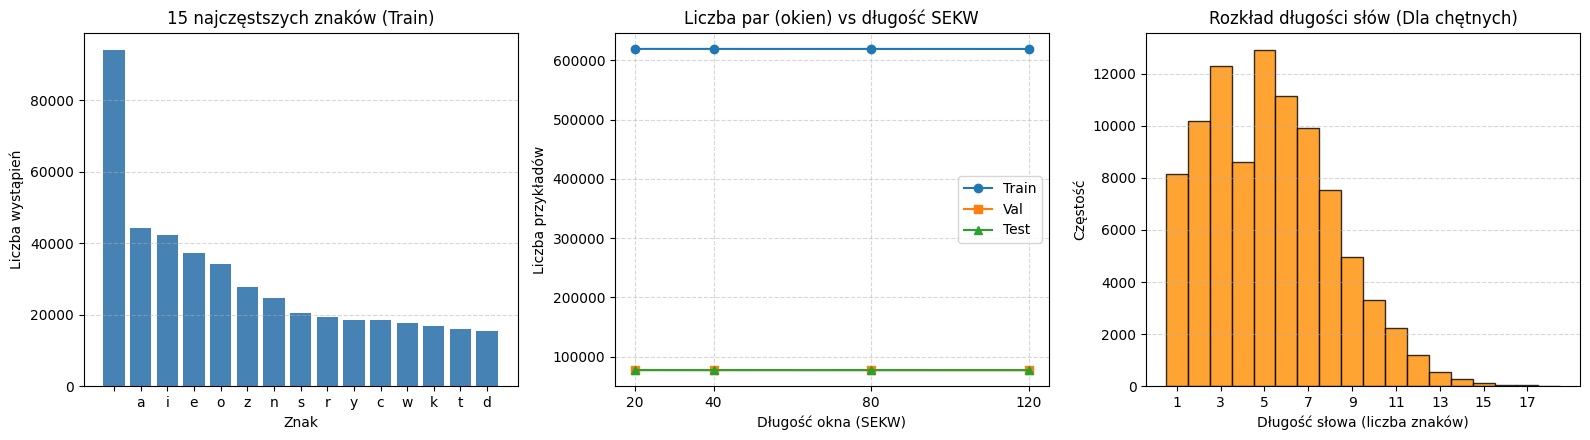


Najczęstsze słowa w zbiorze treningowym (Dla chętnych):
[('i', 2856), ('się', 2565), ('w', 1988), ('nie', 1715), ('na', 1698), ('z', 1478), ('do', 1216), ('że', 1078), ('a', 1064), ('to', 833)]


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

char_counts = Counter(train_text).most_common(15)
labels_c = [repr(c)[1:-1] if c in [' ', '\n'] else c for c, _ in char_counts]
vals_c = [cnt for _, cnt in char_counts]

axes[0].bar(labels_c, vals_c, color='steelblue')
axes[0].set_title('15 najczęstszych znaków (Train)')
axes[0].set_xlabel('Znak')
axes[0].set_ylabel('Liczba wystąpień')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

for name, marker in zip(['Train', 'Val', 'Test'], ['o', 's', '^']):
    axes[1].plot(sekw_lista, wyniki_sekw[name], marker=marker, label=name)
axes[1].set_title('Liczba par (okien) vs długość SEKW')
axes[1].set_xlabel('Długość okna (SEKW)')
axes[1].set_ylabel('Liczba przykładów')
axes[1].set_xticks(sekw_lista)
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

slowa = re.findall(r'\b\w+\b', train_text.lower())
dlugosci_slow = [len(w) for w in slowa if len(w) <= 18]
axes[2].hist(dlugosci_slow, bins=range(1, 20), align='left', color='darkorange', edgecolor='black', alpha=0.8)
axes[2].set_title('Rozkład długości słów')
axes[2].set_xlabel('Długość słowa (liczba znaków)')
axes[2].set_ylabel('Częstość')
axes[2].set_xticks(range(1, 19, 2))
axes[2].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('wykresy_lab6.png', dpi=150)
plt.show()

print("\nNajczęstsze słowa w zbiorze treningowym:")
print(Counter(slowa).most_common(10))